# Flow Q2 — Log-law fit: preparation (Steps 1 and 2)

Data: the 14 files in `Velocity files for FSI/` (see `FlowQ1.ipynb` for the per-file time series). Each file is a dimensionless time series $(\tilde t, \tilde u, \tilde v)$ measured at one fixed height $z/h$ above a rough bed. Velocities are normalised by the mean velocity $U$, time by $h/U$.

**File format:** plain ASCII, no header, whitespace-separated, 3 columns: $\tilde t$, $\tilde u$, $\tilde v$.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# data folder: next to the notebook, or one level up (notebook in a sub-folder)
DATA_DIR = next(p for p in [Path("Velocity files for FSI"), Path("../Velocity files for FSI")] if p.exists())
FILES = sorted(p.name for p in DATA_DIR.glob("Z_*.dat"))

def load_measurement(filename):
    """Load one file -> (DataFrame with columns t, u, v ; z/h from the file name)."""
    path = DATA_DIR / filename
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["t", "u", "v"])
    z_over_h = round(float(path.stem.split("_")[1]) / 100, 4)   # 'Z_23.3' -> 0.233
    return df, z_over_h

print(f"{len(FILES)} files:", FILES)

14 files: ['Z_02.7.dat', 'Z_07.3.dat', 'Z_10.6.dat', 'Z_16.8.dat', 'Z_23.3.dat', 'Z_29.7.dat', 'Z_36.0.dat', 'Z_42.4.dat', 'Z_48.8.dat', 'Z_55.3.dat', 'Z_61.5.dat', 'Z_74.4.dat', 'Z_87.0.dat', 'Z_94.4.dat']


## Goal

The goal is to fit the log law to the vertical profile of the mean streamwise velocity:

$$u(z) = \frac{u_*}{\kappa}\ln\frac{z}{z_0}, \qquad \kappa = 0.41$$

which in the dimensionless variables of this data set becomes a straight line in $\ln(z/h)$:

$$\bar{\tilde u} = a\,\ln(z/h) + b, \qquad a = \frac{u_*}{\kappa U}, \qquad b = a\ln(h/z_0).$$

This section covers only **Step 1** (time-average every file) and **Step 2** (look at the profile to choose the fit range). The regression itself is done later.

**Heights:** $z/h$ comes from the file name (`Z_23.3.dat` → $z/h = 0.233$), as described in `% README.txt`.

## Step 1 — Time-average each file

For every file (= one height $z/h$) we compute:

| quantity | definition | meaning |
|---|---|---|
| `u_mean`, `v_mean` | $\overline{\tilde u}$, $\overline{\tilde v}$ | time-averaged velocities |
| `u_std`, `v_std` | $\sqrt{\overline{\tilde u'^2}}$, $\sqrt{\overline{\tilde v'^2}}$ | turbulence intensities |
| `uv` | $\overline{\tilde u'\tilde v'} = \overline{(\tilde u-\bar{\tilde u})(\tilde v-\bar{\tilde v})}$ | Reynolds stress (dimensionless). Kept for an independent check of the bed shear stress, since theory gives $-\overline{\tilde u'\tilde v'} = (u_*/U)^2(1-z/h)$ |
| `u_mean_1st`, `u_mean_2nd`, `du_halves` | mean of $\tilde u$ over the first and second half of the record, and their difference | **convergence check**: if the record is long enough, both halves give (almost) the same mean |

The files are read with `pandas.read_csv` (C engine) and all statistics are vectorised numpy operations. There is no Python loop over samples. The result is saved to `profile_stats.csv`, so later steps don't have to reload the large files.

In [2]:
def file_stats(filename):
    """Time-averaged statistics of one measurement file (all values dimensionless)."""
    df, zh = load_measurement(filename)
    u = df["u"].to_numpy()
    v = df["v"].to_numpy()
    u_mean, v_mean = u.mean(), v.mean()
    half = len(u) // 2
    u1, u2 = u[:half].mean(), u[half:].mean()
    return {
        "file": filename,
        "z/h": zh,
        "N": len(u),
        "duration_t": df["t"].iloc[-1] - df["t"].iloc[0],
        "u_mean": u_mean,
        "v_mean": v_mean,
        "u_std": u.std(),
        "v_std": v.std(),
        "uv": np.mean((u - u_mean) * (v - v_mean)),   # Reynolds stress <u'v'>
        "u_mean_1st": u1,
        "u_mean_2nd": u2,
        "du_halves": u2 - u1,
    }

stats = pd.DataFrame([file_stats(f) for f in FILES]).sort_values("z/h").reset_index(drop=True)
stats["du_halves_rel_%"] = 100 * stats["du_halves"] / stats["u_mean"]

stats.to_csv("profile_stats.csv", index=False)
print("Saved to profile_stats.csv")
stats.drop(columns=["u_mean_1st", "u_mean_2nd"]).round(5)

Saved to profile_stats.csv


,file,z/h,N,duration_t,u_mean,v_mean,u_std,v_std,uv,du_halves,du_halves_rel_%
0,Z_02.7.dat,0.027,1081344,646.7381,0.42801,0.0,0.11852,0.06339,-0.00319,0.00210,0.48981
1,Z_07.3.dat,0.073,1142784,683.4846,0.64252,-0.0,0.15147,0.07777,-0.00543,-0.00706,-1.09879
2,Z_10.6.dat,0.106,1134592,678.5851,0.71085,-0.0,0.15362,0.07947,-0.00556,-0.02708,-3.80989
3,Z_16.8.dat,0.168,1067008,638.1639,0.83158,-0.0,0.14979,0.07979,-0.00561,-0.02307,-2.77399
4,Z_23.3.dat,0.233,1138688,681.0348,0.91985,-0.0,0.14105,0.07857,-0.00506,-0.00855,-0.92978
5,Z_29.7.dat,0.297,1187840,710.4320,0.97166,-0.0,0.13581,0.07648,-0.00480,-0.01690,-1.73922
6,Z_36.0.dat,0.360,1685504,1008.0788,1.02020,-0.0,0.12014,0.07223,-0.00401,0.00704,0.68959
7,Z_42.4.dat,0.424,1089536,651.6376,1.02522,0.0,0.11981,0.07153,-0.00387,-0.02535,-2.47230
8,Z_48.8.dat,0.488,1085440,649.1878,1.07753,-0.0,0.11008,0.06820,-0.00320,0.00491,0.45562
9,Z_55.3.dat,0.553,1538048,919.8872,1.11099,-0.0,0.09862,0.06391,-0.00247,0.00169,0.15183


**Reload later without the big files:**
```python
stats = pd.read_csv("profile_stats.csv")
```

## Step 2 — Choosing the fit range for the log law

The log law $\bar{\tilde u} = a\ln(z/h) + b$ is only valid in part of the water column. Step 2 decides **which points to use in the fit**, in three sub-steps (2a–2c).
It only uses the time-averaged results from Step 1 (`profile_stats.csv`). The raw data files are not reloaded.

In [3]:
# Shared setup for Step 2: load the Step 1 results + common plot style
stats = pd.read_csv("profile_stats.csv").sort_values("z/h").reset_index(drop=True)
zh   = stats["z/h"].to_numpy()
umn  = stats["u_mean"].to_numpy()
lnz  = np.log(zh)
KAPPA = 0.41
LIMITS = [0.2, 0.3, 0.5]                       # candidate upper limits of the fit range

BLUE, ORANGE = "#2a78d6", "#eb6834"
U_LABEL = r"$\overline{\tilde u} = \bar u / U$"
Z_LABEL = r"$z/h$  (log scale)"
YLIM = (0.02, 1.0)

def semilog_profile(ax, title):
    # Semilog profile: u_mean/U horizontal, z/h vertical (log). Log law = straight line.
    for lim in LIMITS:
        ax.axhline(lim, color="0.45", lw=0.8, ls=":")
        ax.text(0.405, lim, f" $z/h = {lim}$", va="bottom", fontsize=8, color="0.35")
    ax.plot(umn, zh, "o", color=BLUE, ms=7, mec="white", mew=1.5, zorder=3, label="measured")
    for i, (x, y) in enumerate(zip(umn, zh)):
        ax.annotate(f"{i}: {y:.3f}", (x, y), xytext=(6, -3), textcoords="offset points",
                    fontsize=7, color="0.35")
    ax.set_yscale("log")
    ax.set_ylim(*YLIM)
    ax.set_xlim(0.4, 1.25)
    ax.set_xlabel(U_LABEL)
    ax.set_ylabel(Z_LABEL)
    ax.set_title(title)
    ax.grid(True, which="both", color="0.88", lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

### Step 2a — Why the log law only holds near the bed

The log law follows from assuming a **constant** shear stress $\tau \approx \tau_b$ together with a mixing length $\ell = \kappa z$. In a uniform open-channel flow the shear stress actually decreases linearly from the bed to the free surface:

$$\tau(z) = \tau_b\,(1 - z/h).$$

So $\tau \approx \tau_b$ is only a reasonable approximation close to the bed. Higher up, $\tau$ is much smaller than $\tau_b$ and the measured profile departs from the log law (wake region). The table shows how quickly the assumption breaks down.

In [4]:
z_check = np.array([0.05, 0.2, 0.5, 0.9])
pd.DataFrame({"z/h": z_check, "tau/tau_b = 1 - z/h": 1 - z_check}).style.hide(axis="index").format("{:.2f}")

z/h,tau/tau_b = 1 - z/h
0.05,0.95
0.20,0.80
0.50,0.50
0.90,0.10


### Step 2b — Semilog profile plot

Plot $\bar{\tilde u}$ against $z/h$ on a logarithmic axis. In this representation the log law is a **straight line**, so the log region can be recognised by eye. Each point is labelled `index: z/h`, and the candidate upper limits $z/h = 0.2,\ 0.3,\ 0.5$ are shown as dotted lines.

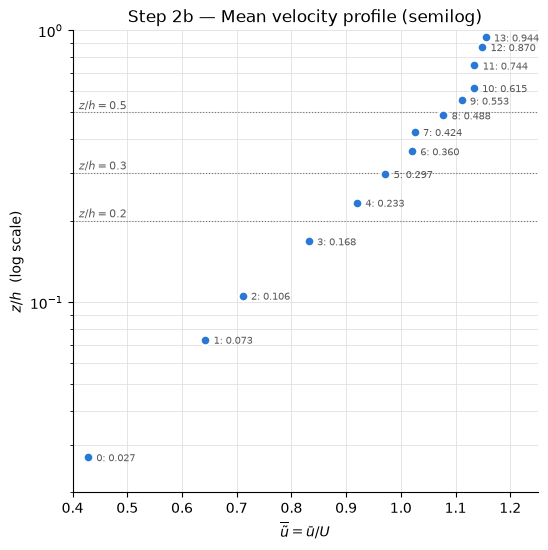

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
semilog_profile(ax, "Step 2b — Mean velocity profile (semilog)")
plt.show()

### Step 2c — Visual inspection

The same plot with a straight reference line, fitted through only the **lowest 4 points** and extended over the full depth. This shows where the measured points start to leave the line. Separately, the lowest point is compared with a line through the 3 points just above it, to see whether it lies in the roughness layer.

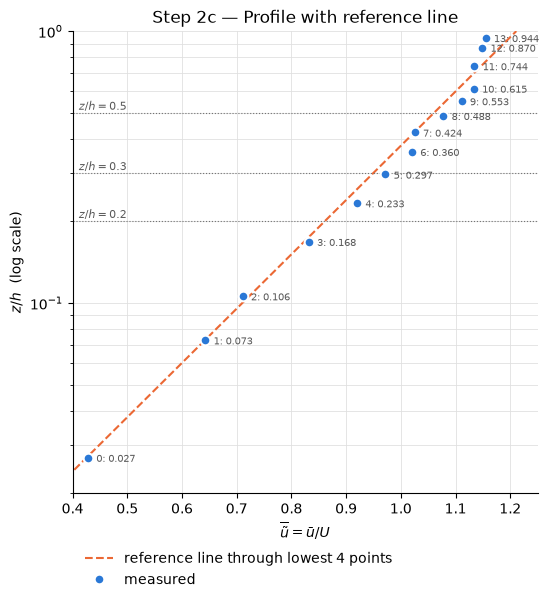

Reference line: a = 0.2175, b = 1.2111
Deviation from the reference line (measured - line):
   0  z/h = 0.027:  +0.003
   1  z/h = 0.073:  +0.001
   2  z/h = 0.106:  -0.012
   3  z/h = 0.168:  +0.009
   4  z/h = 0.233:  +0.026
   5  z/h = 0.297:  +0.025
   6  z/h = 0.360:  +0.031
   7  z/h = 0.424:  +0.001
   8  z/h = 0.488:  +0.023
   9  z/h = 0.553:  +0.029
  10  z/h = 0.615:  +0.028
  11  z/h = 0.744:  -0.012
  12  z/h = 0.870:  -0.032
  13  z/h = 0.944:  -0.044

Lowest point (z/h = 0.027): measured 0.428, line through points 1-3 predicts 0.410 -> difference +0.018 (+4.5 %)


In [6]:
N_REF = 4
a_ref, b_ref = np.polyfit(lnz[:N_REF], umn[:N_REF], 1)
z_line = np.geomspace(*YLIM, 100)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(a_ref * np.log(z_line) + b_ref, z_line, "--", color=ORANGE, lw=1.5,
        label=f"reference line through lowest {N_REF} points")
semilog_profile(ax, "Step 2c — Profile with reference line")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False)
plt.show()

dev = umn - (a_ref * lnz + b_ref)
print(f"Reference line: a = {a_ref:.4f}, b = {b_ref:.4f}")
print("Deviation from the reference line (measured - line):")
for i, (z, d) in enumerate(zip(zh, dev)):
    print(f"  {i:2d}  z/h = {z:.3f}:  {d:+.3f}")

# Roughness-layer check: does point 0 follow the line through points 1-3?
a13, b13 = np.polyfit(lnz[1:4], umn[1:4], 1)
pred0 = a13 * lnz[0] + b13
print(f"\nLowest point (z/h = {zh[0]:.3f}): measured {umn[0]:.3f}, line through points 1-3 predicts {pred0:.3f} "
      f"-> difference {umn[0] - pred0:+.3f} ({100 * (umn[0] - pred0) / pred0:+.1f} %)")

#### Step 2c (continued) — Line fitted without the highest points

Two extra versions of the same plot. Here the straight line is fitted through **all points except the 2 highest** and **all points except the 3 highest** (the points closest to the free surface). If those near-surface points are the only ones that don't follow the log law, the remaining points should lie on the line without a systematic trend. The excluded points are drawn as open markers.

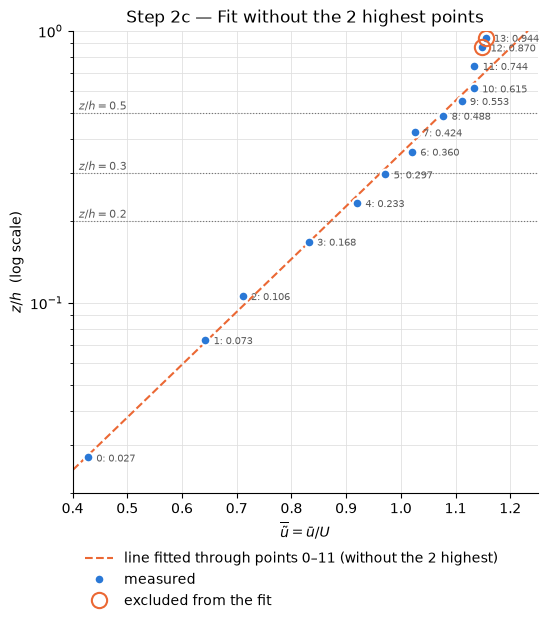

Without the 2 highest points: a = 0.2237, b = 1.2323, u*/U = kappa*a = 0.0917
  deviation (measured - line): 0: +0.004, 1: -0.004, 2: -0.019, 3: -0.002, 4: +0.013, 5: +0.011, 6: +0.017, 7: -0.015, 8: +0.006, 9: +0.011, 10: +0.010, 11: -0.032, 12: -0.052, 13: -0.064



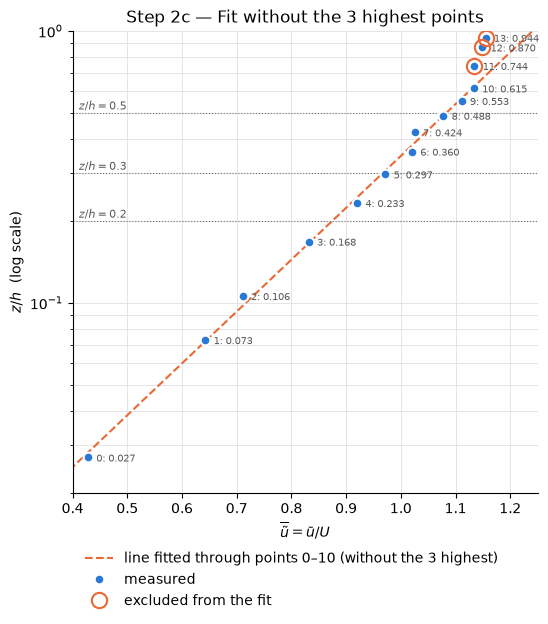

Without the 3 highest points: a = 0.2278, b = 1.2412, u*/U = kappa*a = 0.0934
  deviation (measured - line): 0: +0.009, 1: -0.003, 2: -0.019, 3: -0.003, 4: +0.010, 5: +0.007, 6: +0.012, 7: -0.021, 8: -0.000, 9: +0.005, 10: +0.003, 11: -0.039, 12: -0.061, 13: -0.073



In [7]:
for n_drop in (2, 3):
    keep = np.arange(len(zh)) < len(zh) - n_drop          # leave out the n_drop highest points
    a_d, b_d = np.polyfit(lnz[keep], umn[keep], 1)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(a_d * np.log(z_line) + b_d, z_line, "--", color=ORANGE, lw=1.5,
            label=f"line fitted through points 0–{len(zh) - n_drop - 1} (without the {n_drop} highest)")
    semilog_profile(ax, f"Step 2c — Fit without the {n_drop} highest points")
    ax.plot(umn[~keep], zh[~keep], "o", ms=11, mfc="none", mec=ORANGE, mew=1.5, zorder=4,
            label="excluded from the fit")
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False)
    plt.show()

    dev_d = umn - (a_d * lnz + b_d)
    print(f"Without the {n_drop} highest points: a = {a_d:.4f}, b = {b_d:.4f}, u*/U = kappa*a = {KAPPA * a_d:.4f}")
    print("  deviation (measured - line): " + ", ".join(f"{i}: {d:+.3f}" for i, d in enumerate(dev_d)))
    print()

**What is visible.**
- **Points 0–3** ($z/h \le 0.17$) define the reference line.
- **Points 4–10** ($0.23 \le z/h \le 0.62$) lie about 0.02–0.03 to the right of it, but they still form a roughly straight band with a similar slope. Point 7 ($z/h = 0.424$) is an outlier: it also has the largest first-half/second-half difference in Step 1.
- **Above $z/h \approx 0.6$** (points 11–13) the profile clearly bends. The velocity hardly increases any more, and the points cross to the left of the line.
- **Lowest point:** it is only about 0.02 (≈ 4 %) faster than the line through points 1–3 predicts. That is comparable to the scatter of the other points, so there is **no clear sign** of a roughness-layer deviation in the mean velocity.

## Step 3 — Bed shear stress from the log-law fit

A straight line is fitted through **all 14 points** of $\bar u/U$ against $\ln(z/h)$:

$$\frac{\bar u}{U} = a\ln(z/h) + b, \qquad a = \frac{u_*}{\kappa U}$$

The slope $a$ gives the friction velocity $u_* = \kappa a U$, and from that the bed shear stress $\tau_b = \rho u_*^2$.

Input values from the assignment: $h = 25$ m, $U = 1.5$ m/s, $\rho = 1025$ kg/m³, $\kappa = 0.41$.

a      = 0.2142
b      = 1.2123
u*     = kappa * a * U = 0.1317 m/s
tau_b  = rho * u*^2    = 17.8 N/m2


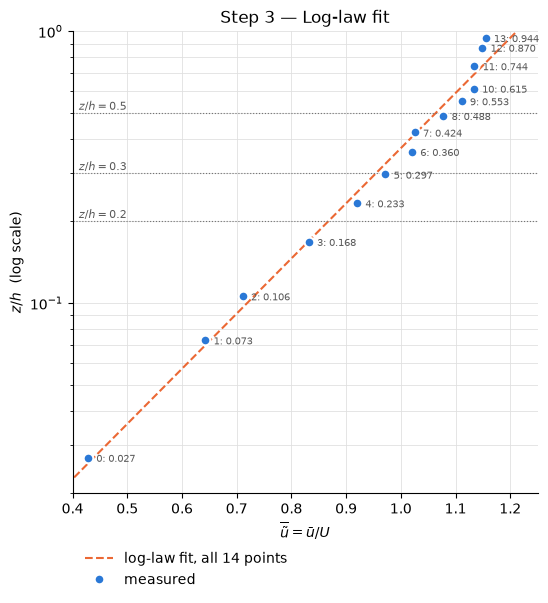

In [8]:
h, U, RHO, KAPPA = 25.0, 1.5, 1025.0, 0.41

stats = pd.read_csv("profile_stats.csv").sort_values("z/h")
zh, umn = stats["z/h"].to_numpy(), stats["u_mean"].to_numpy()

a, b = np.polyfit(np.log(zh), umn, 1)     # straight line through all 14 points
u_star = KAPPA * a * U                     # friction velocity [m/s]
tau_b  = RHO * u_star**2                   # bed shear stress [N/m2]

print(f"a      = {a:.4f}")
print(f"b      = {b:.4f}")
print(f"u*     = kappa * a * U = {u_star:.4f} m/s")
print(f"tau_b  = rho * u*^2    = {tau_b:.1f} N/m2")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(a * np.log(z_line) + b, z_line, "--", color=ORANGE, lw=1.5, label="log-law fit, all 14 points")
semilog_profile(ax, "Step 3 — Log-law fit")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), frameon=False)
plt.show()

**Result:** the fit through all 14 points gives $a$ and $b$ (printed above). From these follow $u_* \approx 0.13$ m/s and a bed shear stress of $\tau_b \approx 18$ N/m².